# Part 1: Probability Distributions – EM Algorithm


We have one list of heights from two populations (Fathers and Children) **without labels**.
We treat it as a mixture of two Gaussians and use the **Expectation-Maximization (EM)** algorithm, written from scratch, to find:
- **μ** – the mean height of each group
- **σ²** – the variance (spread) of each group
- **π** – the mixing weight (share of the data in each group)

In [ ]:
import glob
import numpy as np
import em_gmm as em

# Finds the Kaggle CSV in this folder automatically (or type its name instead)
CSV_PATH = glob.glob("*.csv")[0]
PARENT = "father"                 # or "mother"
print("Using:", CSV_PATH)

Using: GaltonFamilies.csv


## 1. Load the data
We merge parents and children into ONE unlabeled list. The true labels are kept aside only to check our results at the end.

In [ ]:
heights, true_labels = em.load_heights(CSV_PATH, parent=PARENT)
print(f"{len(heights)} heights | min {heights.min():.1f} | max {heights.max():.1f} | mean {heights.mean():.2f}")

1139 heights | min 56.0 | max 79.0 | mean 67.21


## 2. How EM works
**Initialization:** means at the 25th and 75th percentiles, both variances = overall variance, π1 = π2 = 0.5.

**E-step (Expectation):** for every height, compute the *responsibility* – the probability it belongs to each group:
$$r_{ik} = \frac{\pi_k \, N(x_i \mid \mu_k, \sigma_k^2)}{\sum_j \pi_j \, N(x_i \mid \mu_j, \sigma_j^2)}$$

**M-step (Maximization):** update the parameters, using responsibilities as weights:
$$N_k = \sum_i r_{ik}, \quad \mu_k = \frac{1}{N_k}\sum_i r_{ik} x_i, \quad \sigma_k^2 = \frac{1}{N_k}\sum_i r_{ik}(x_i-\mu_k)^2, \quad \pi_k = \frac{N_k}{n}$$

**Stopping rule:** repeat until the log-likelihood $\sum_i \log \sum_k \pi_k N(x_i \mid \mu_k, \sigma_k^2)$ changes by less than $10^{-6}$.

In [ ]:
params, history = em.fit_em(heights, tol=1e-6)

Converged after 319 iterations (log-likelihood change 9.79e-07 < 1e-06)


## 3. Tracking table (initialization + first two iterations)

In [ ]:
em.tracking_table(history, rows=3)

,mu1 (shorter),mu2 (taller),sigma1^2,sigma2^2,pi1,pi2,Log-Likelihood
Iteration,,,,,,,
0,64.5000,70.0000,12.7241,12.7241,0.5000,0.5000,-3119.8222
1,65.2205,69.2054,9.0603,8.4468,0.5011,0.4989,-3057.9135
2,65.1609,69.2600,8.9420,8.1040,0.5005,0.4995,-3056.9719


The log-likelihood never decreases from one iteration to the next. This is a guaranteed property of EM, and it is why a very small change in log-likelihood is a sensible signal to stop.

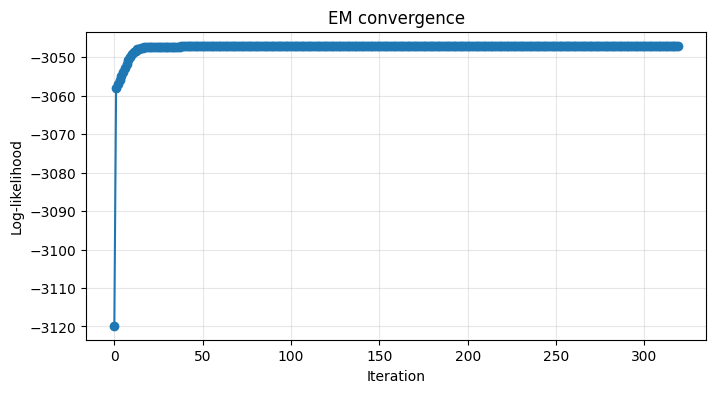

In [ ]:
em.plot_log_likelihood(history, save_path="em_convergence.png")

## 4. Final fitted Gaussians

Final parameters:
  Component 1 (shorter): mu = 64.177, sigma^2 = 5.302, pi = 0.432
  Component 2 (taller): mu = 69.519, sigma^2 = 6.041, pi = 0.568


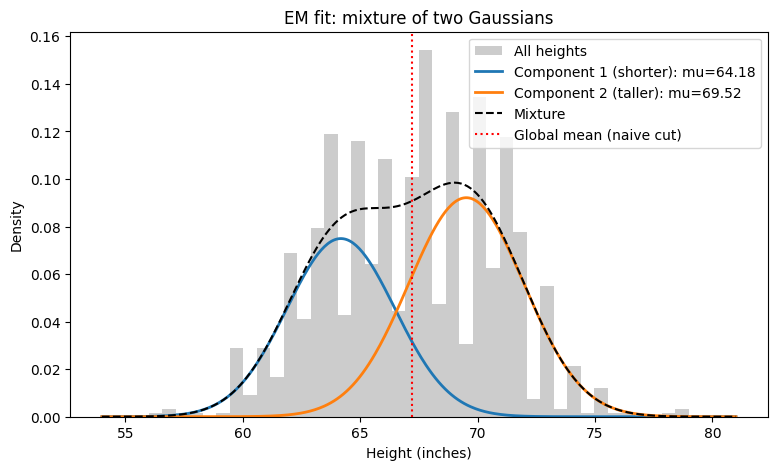

In [ ]:
print("Final parameters:")
for k, name in enumerate(em.GROUP_NAMES):
    print(f"  {name}: mu = {params['mu'][k]:.3f}, sigma^2 = {params['var'][k]:.3f}, pi = {params['pi'][k]:.3f}")
em.plot_fit(heights, params, save_path="em_fit.png")

## 5. Live test: classify a height given by the coach

In [ ]:
def demonstrate_height(params):
    """Validate a height and show its component probabilities."""
    try:
        height = float(input("Height in inches: "))
    except ValueError:
        print("Enter a number, such as 65.")
        return

    if not np.isfinite(height) or height <= 0:
        print("Enter a finite number greater than zero.")
        return

    names = em.GROUP_NAMES
    return em.classify_height(height, params, names=names)

In [ ]:
test_probabilities = demonstrate_height(params)

Height in inches: 65
Test height: 65.0
  P(Component 1 (shorter) | height) = 0.805269  (80.53%)
  P(Component 2 (taller) | height) = 0.194731  (19.47%)
  -> Most likely: Component 1 (shorter)


## Interactive height test

Enter a height in inches to display both fitted-component
probabilities. Invalid inputs are rejected.

Component membership does not automatically establish whether
someone is a child or parent.

## 6. Should we just split at the global mean?
**No.** Cutting at the global mean and averaging each pile is a *hard* split:
1. **Misclassification:** the two groups overlap. A height near the mean could be either group, but a hard cut forces it into one pile with 100% certainty.
2. **Biased means:** tall children land in the taller pile and short fathers land in the shorter pile, so both pile means are pulled away from the true means.
3. **Ignores spread and group size:** the cut is always at the mean, even when one group is bigger or more spread out.

EM uses soft assignments: a height that is 60% likely to belong to Component 1 and 40% to Component 2 counts 0.6 towards the Component 1 mean and 0.4 towards the Component 2 mean, and EM also learns variances and weights.

In [ ]:
naive = em.global_mean_split(heights)
print(f"Global mean cut at {naive['cut']:.2f}")
em.compare_methods(heights, true_labels, params)

Global mean cut at 67.21


,True labels,Global-mean split,EM
Mean of Children,66.746,64.260,64.177
Mean of Parents,69.316,70.215,69.519
Accuracy,1.000,0.608,0.565


In [ ]:
labels = np.asarray(true_labels)      # 0 = child, 1 = father
cut = naive["cut"]

predictions = {
    "Global-mean split": (heights >= cut).astype(int),
    "EM (taller component = father)": (em.e_step(heights, params)[:, 1] > 0.5).astype(int),
    "Always predict child": np.zeros_like(labels),
}

def score(y_true, y_pred):
    """Accuracy plus recall for each class, and their average (balanced accuracy)."""
    accuracy = np.mean(y_true == y_pred)
    child_recall = np.mean(y_pred[y_true == 0] == 0)
    father_recall = np.mean(y_pred[y_true == 1] == 1)
    return accuracy, child_recall, father_recall, (child_recall + father_recall) / 2

print(f"{'Method':<32}{'Accuracy':>9}{'Child recall':>14}{'Father recall':>15}{'Balanced acc':>14}")
for name, pred in predictions.items():
    acc, cr, fr, ba = score(labels, pred)
    print(f"{name:<32}{acc:>9.3f}{cr:>14.3f}{fr:>15.3f}{ba:>14.3f}")

Method                           Accuracy  Child recall  Father recall  Balanced acc
Global-mean split                   0.608         0.569          0.785         0.677
EM (taller component = father)      0.565         0.505          0.839         0.672
Always predict child                0.820         1.000          0.000         0.500


Accuracy alone is misleading because 934 of the 1,139 observations are children. Always predicting “child” gives 82.0% accuracy but identifies no fathers. Its balanced accuracy—the average recall across both groups—is therefore 50.0%.

The global-mean split achieves 67.7% balanced accuracy, compared with 67.2% for EM. EM identifies more fathers correctly (83.9% versus 78.5%), while the mean split identifies more children correctly (56.9% versus 50.5%). Neither reliably separates the demographic groups.

EM’s benefit here is soft membership probabilities and learned component means, variances and mixing weights, rather than improved classification accuracy.


In [ ]:
labels = np.asarray(true_labels)
print("Label values:", np.unique(labels, return_counts=True))

Label values: (array([0, 1]), array([934, 205]))


In [ ]:
import pandas as pd
df = pd.read_csv(CSV_PATH)
kids = df[["childHeight", "gender"]].copy()
probs = em.e_step(kids["childHeight"].to_numpy(dtype=float), params)
kids["in_taller_component"] = probs[:, 1] > 0.5
print(kids.groupby("gender")["in_taller_component"].mean().round(3))

gender
female    0.135
male      0.834
Name: in_taller_component, dtype: float64


**Result: EM mostly split the children by sex.** Among the 934 children, 83.4% of the sons fall in the taller component (Component 2), while only 13.5% of the daughters do. So EM mainly found a shorter group (mostly daughters) and a taller group (mostly sons and fathers). This test uses the children's heights and sex only; it does not show that EM can separate fathers from children.

7. Conclusion

Convergence. To obtain this log-likelihood, EM stopped after 319 iterations, with a change of 9.79e-07 (less than 0.000001) between iterations. The log-likelihood function will never go down during EM, so if it changes a little bit, the fit is very likely to be at a stationary point, typically a local maximum. This reveals that there was no improvement in the chances. It doesn't indicate that EM discovered the real groups.

The two components. The fitted means are 64.18 and 69.52 inches, with mixing weights 0.432 and 0.568. They're called Component 1 (short) and Component 2 (high).

Is it safe and appropriate to take a global mean cut? No. The average is 67.21 inches. The averages of the two piles are 64.26 and 70.22, the true averages are 66.75 (children) and 69.32 (fathers), and the cut is too far apart. Tall children are given to the tall fathers and the short fathers to the children and each height must inevitably be put in one pile. In the case of EM, however, it assigns a probability to each height.

What surprised us. EM refused to divorce fathers from children. The two means are around average for the heights of females and males, and Galton's “children” are all adults, both male and female, so EM likely discovered a gender dimorphism. The fitted weights (0.432 and 0.568) are also different from the true split (82% children and 18% fathers).

Accuracy. The mean cut scores of 0.608 accuracy and EM scores of 0.565. Both are below the average of "child" (0.820, because 934 of the 1139 heights are children). However, none of the 205 fathers exists in the baseline, which gives its balanced accuracy of 0.500. When the balanced accuracy is calculated, both the mean cut (0.677) and EM (0.672) are comparable and neither is capable of separating fathers and children reliably. The difference between the average height of a father and that of their adult children is only about 2.6 inches.

What we learned. The beauty of EM is the use of soft probabilities and learning the variance and weight of each component. It's not improved label accuracy. The clusters that EM finds that explain the heights may not be the ones that we think they are; this is why it is always important to validate the results to see if they make sense.